Training Yolov8 model on Custom Dataset

In [9]:
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))


GPU Available: True
GPU Name: Tesla T4


In [10]:
!nvidia-smi

Sun May 24 05:01:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#### Training Configuration and overview

In [12]:
path_to_classes_txt='/content/drive/MyDrive/Vehicle_Data/DataSet/classes.txt'
path_to_data_yaml='/content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml'

print('Files Contains:\n')
!cat /content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml

Files Contains:

# paths of folders 
path: /content/drive/MyDrive/Vehicle_Data # root folder path
train: DataSet/train/images # train folder path
val: DataSet/val/images # val folder path

# Number of Classes
nc: 3

# Classes
names:
  0: bicycle
  1: car
  2: bike

#### Install Requirements

In [13]:
!pip install ultralytics

#### Deleting old cache files

In [14]:
!rm -f /content/drive/MyDrive/Vehicle_Data/DataSet/train/images.cache
!rm -f /content/drive/MyDrive/Vehicle_Data/DataSet/val/images.cache
!rm -f /content/drive/MyDrive/Vehicle_Data/DataSet/train/labels.cache
!rm -f /content/drive/MyDrive/Vehicle_Data/DataSet/val/labels.cache

Deleing previous weight

In [15]:
# Also delete the failed run's weights
!rm -rf /content/runs/

#### Run Training

In [16]:
!yolo detect train data=/content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml model=yolov8m.pt epochs=70 imgsz=640 patience=0

Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/Vehicle_Data/DataSet/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=70, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_

#### Listing all the obtained stuffs after training

In [17]:
!ls runs/detect/train/

args.yaml			 results.csv	      val_batch0_labels.jpg
BoxF1_curve.png			 results.png	      val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg     val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg     val_batch1_pred.jpg
BoxR_curve.png			 train_batch2.jpg     val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch3300.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch3301.jpg  weights
labels.jpg			 train_batch3302.jpg


#### Now we display some results we obtained

In [20]:
!pip install Ipython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 74.9 MB/s eta 0:00:00


In [23]:
from IPython.display import Image, display

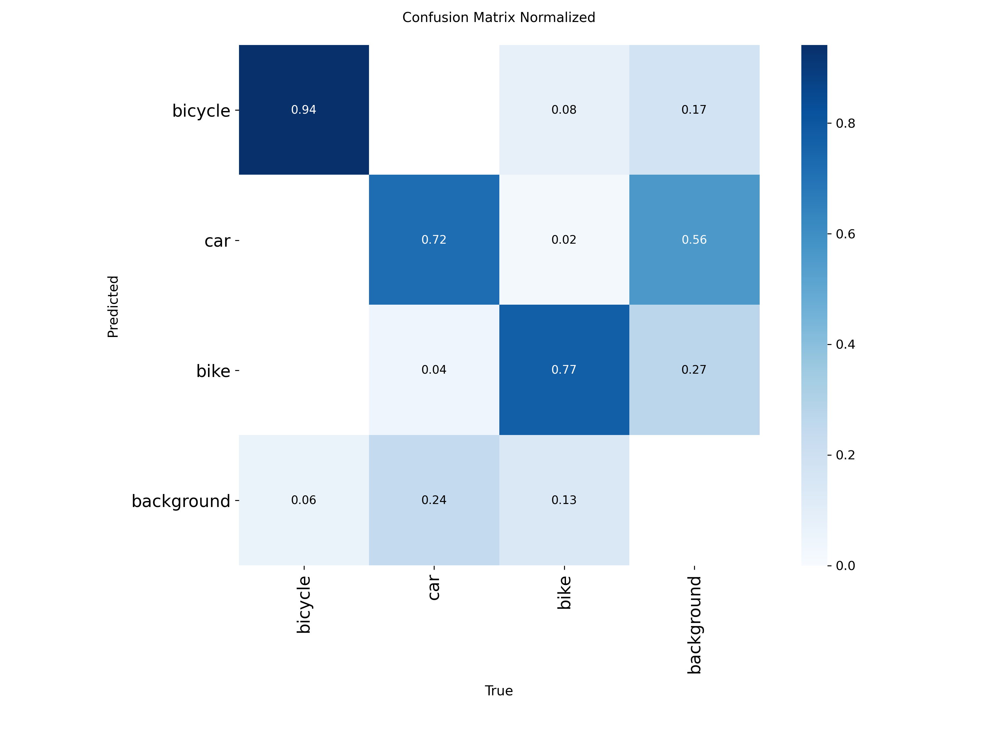

In [25]:
Image(filename='runs/detect/train/confusion_matrix_normalized.png', width=600)

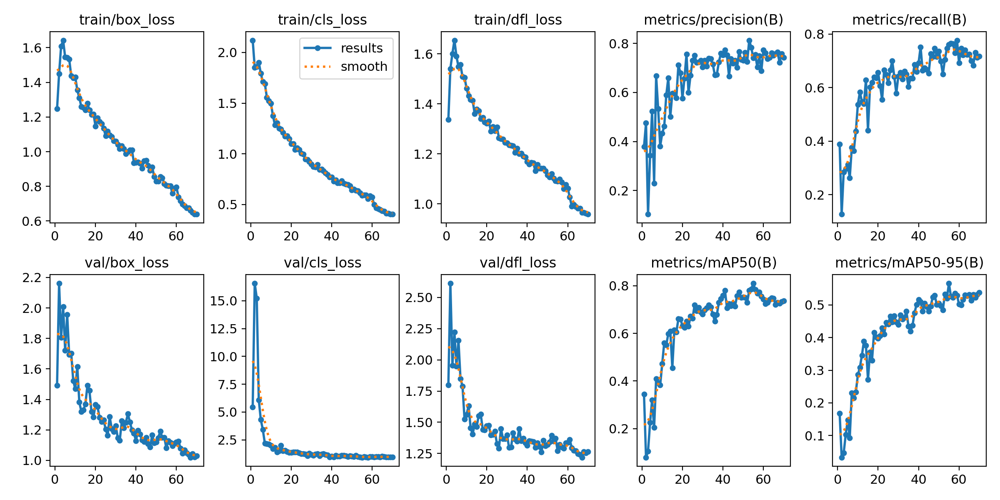

In [29]:
Image(filename='runs/detect/train/results.png',width=700)

### Testing Model
 *Inferencing on validation set. And then displaying first 10 images.*

In [30]:
!yolo detect predict model=/content/runs/detect/train/weights/best.pt source=/content/drive/MyDrive/Vehicle_Data/DataSet/val/images save=True

Ultralytics 8.4.53 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 93 layers, 25,841,497 parameters, 0 gradients, 78.7 GFLOPs

image 1/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_274.jpeg: 448x640 1 bicycle, 57.0ms
image 2/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_275.jpeg: 448x640 1 bicycle, 27.0ms
image 3/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_276.jpeg: 640x448 1 bicycle, 46.6ms
image 4/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_277.jpeg: 448x640 1 bicycle, 27.9ms
image 5/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_278.jpeg: 640x448 3 bicycles, 27.7ms
image 6/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_279.jpeg: 640x448 1 bicycle, 26.9ms
image 7/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/images/Bicycle_280.jpeg: 640x448 1 bicycle, 26.9ms
image 8/96 /content/drive/MyDrive/Vehicle_Data/DataSet/val/imag

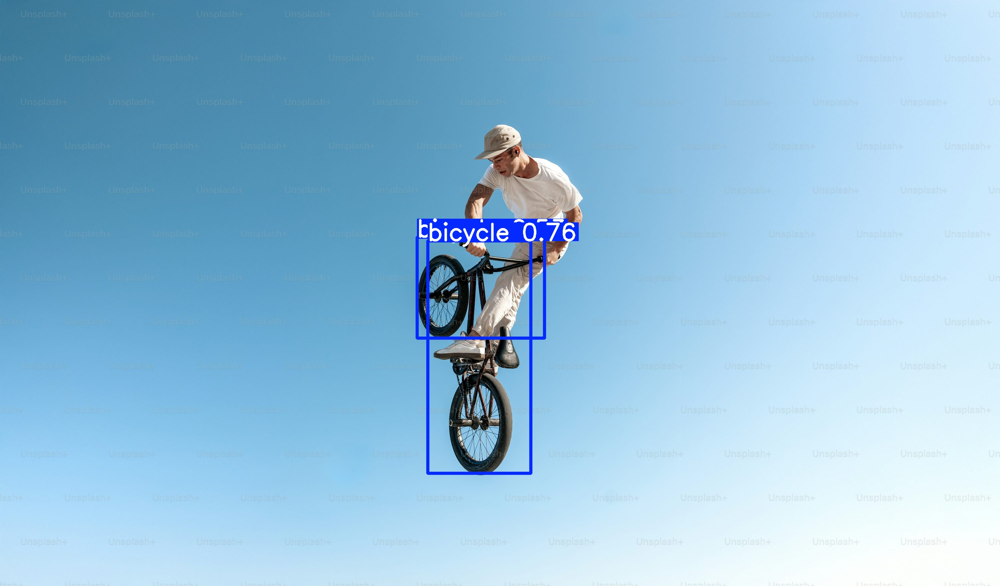

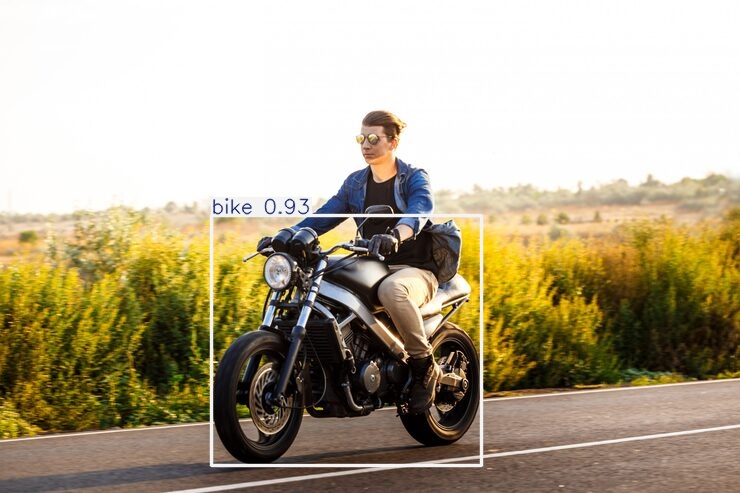

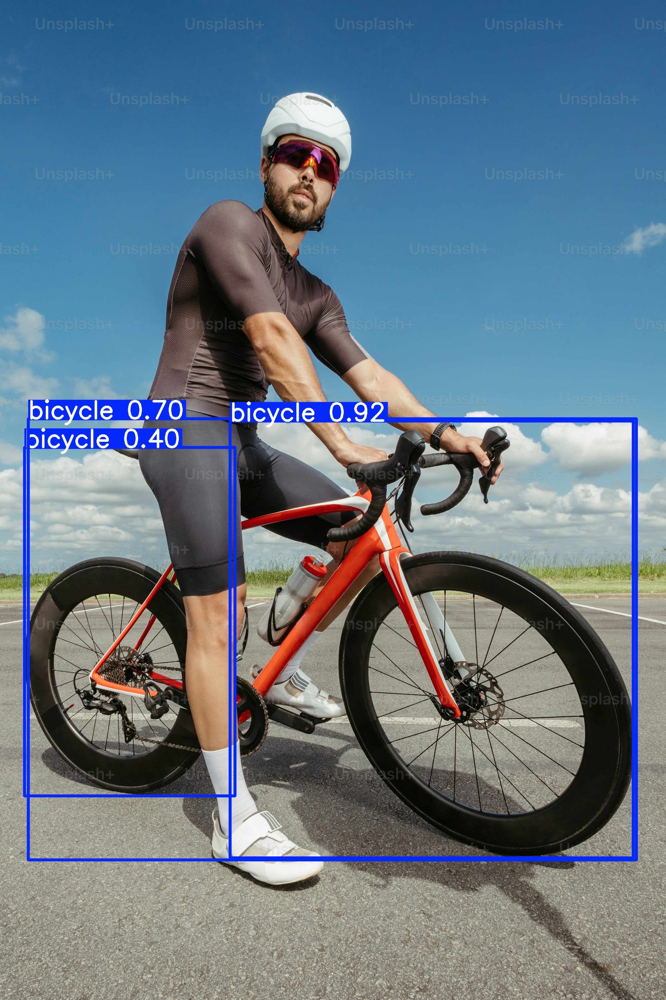

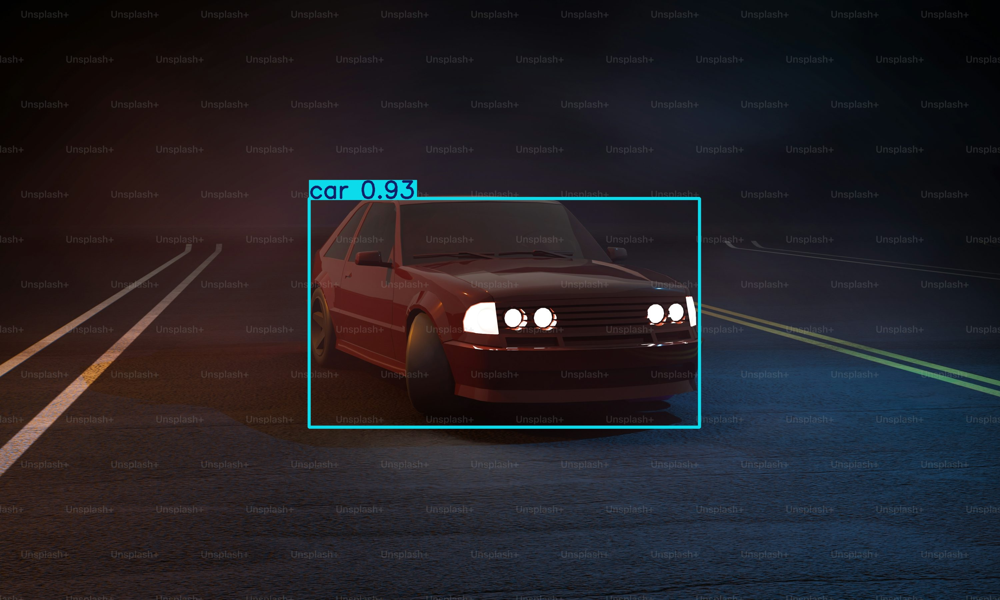

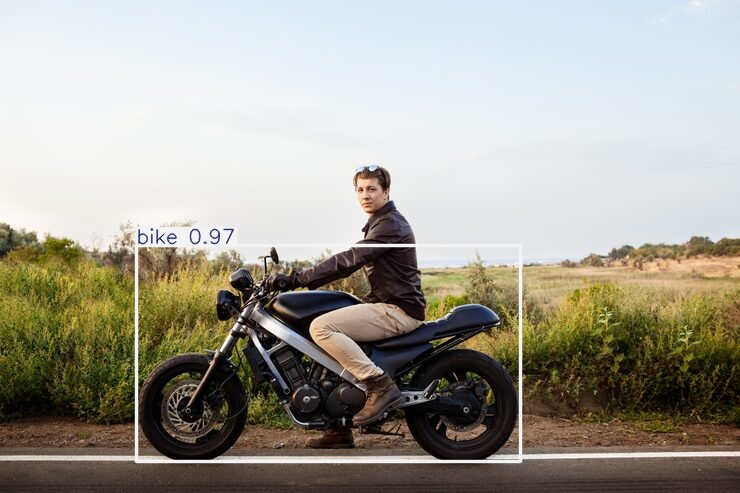

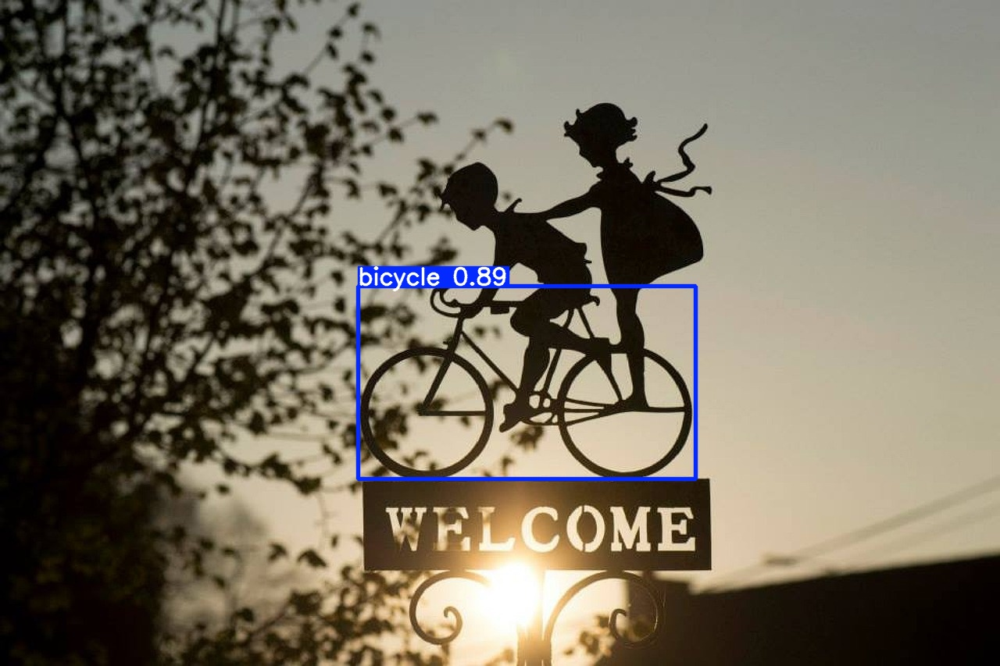

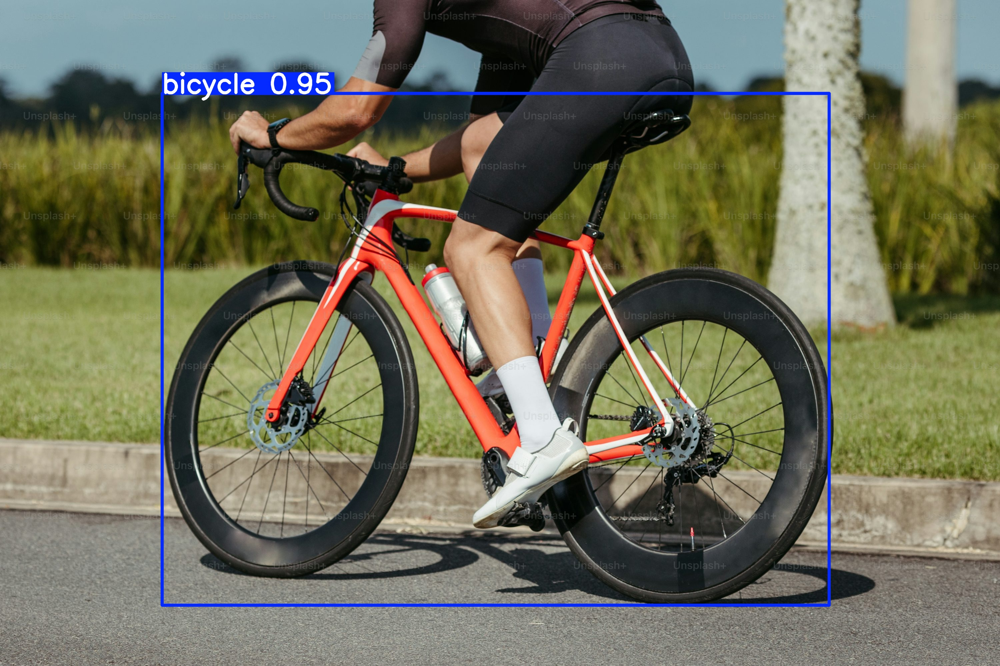

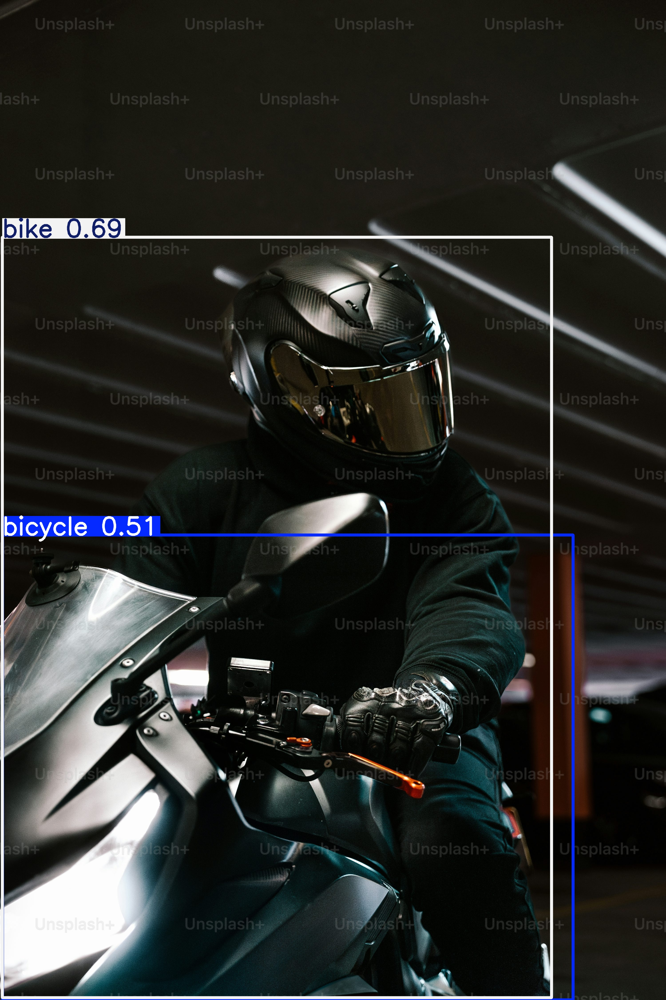

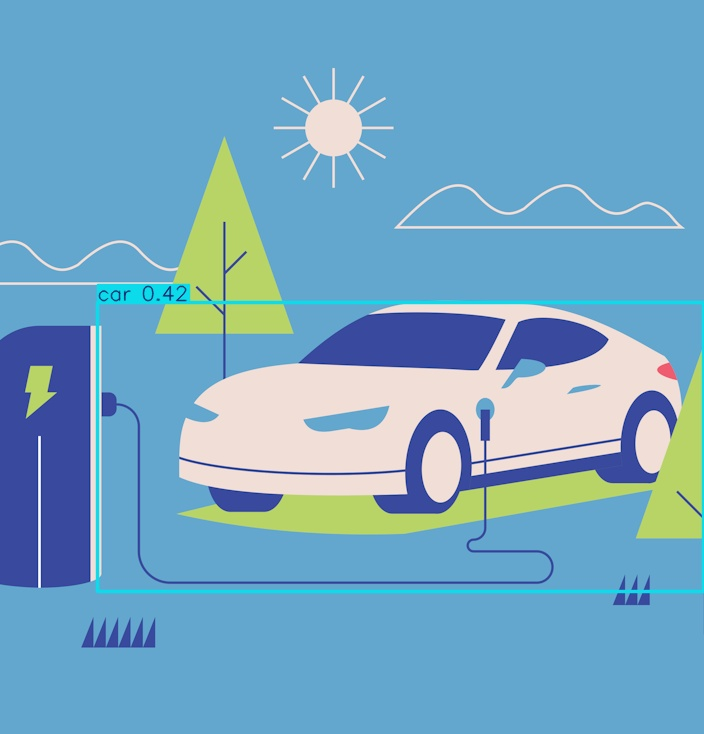

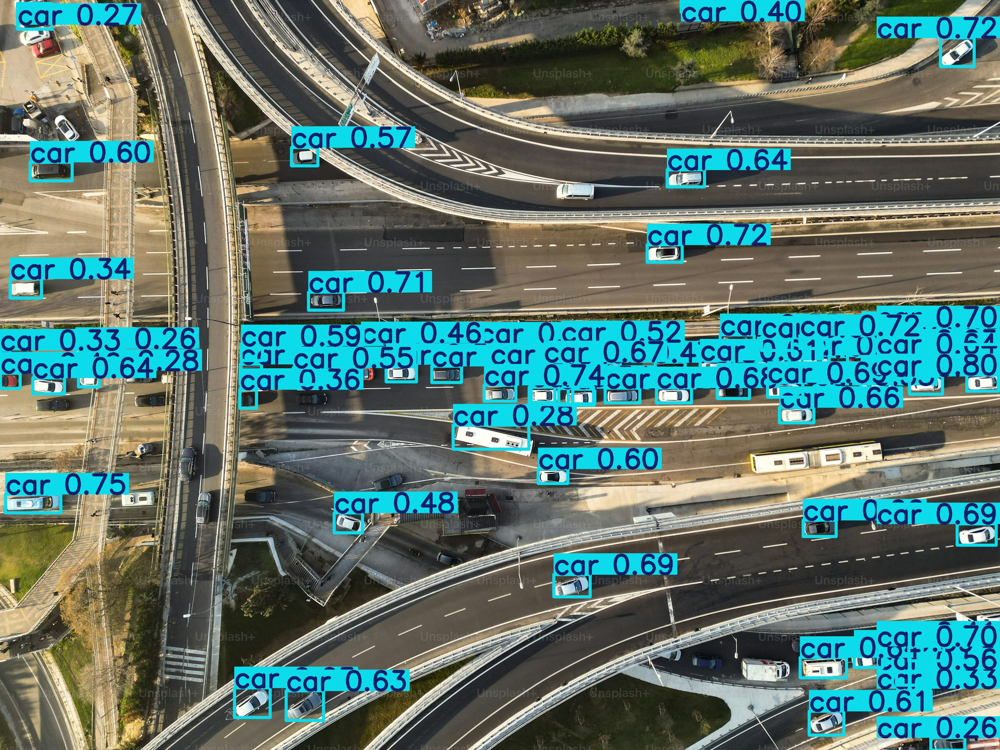

In [34]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
  display(Image(filename=image_path, height=400))
  print('\n')

### Download Trained YOLO model

In [36]:
# Create "my_model" folder to store model weights and train results
!mkdir /content/my_model
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt
!cp -r /content/runs/detect/train /content/my_model

# Zip into "my_model.zip"
%cd my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

#

mkdir: cannot create directory ‘/content/my_model_1’: File exists
/content/my_model_1
  adding: my_model_1.pt (deflated 8%)
  adding: train/ (stored 0%)
  adding: train/train_batch3302.jpg (deflated 11%)
  adding: train/val_batch1_pred.jpg (deflated 13%)
  adding: train/weights/ (stored 0%)
  adding: train/weights/best.pt (deflated 8%)
  adding: train/weights/last.pt (deflated 8%)
  adding: train/train_batch3301.jpg (deflated 13%)
  adding: train/BoxPR_curve.png (deflated 15%)
  adding: train/train_batch2.jpg (deflated 3%)
  adding: train/val_batch2_pred.jpg (deflated 10%)
  adding: train/train_batch3300.jpg (deflated 7%)
  adding: train/val_batch2_labels.jpg (deflated 10%)
  adding: train/confusion_matrix.png (deflated 30%)
  adding: train/train_batch0.jpg (deflated 4%)
  adding: train/val_batch1_labels.jpg (deflated 13%)
  adding: train/val_batch0_labels.jpg (deflated 14%)
  adding: train/results.csv (deflated 61%)
  adding: train/BoxP_curve.png (deflated 12%)
  adding: train/BoxR_cu